### Step 1: Import Libraries and API Key

In [2]:
import os
import random # For random number generation
import json #to describe the tool function to the LLM (example, send_notification_function)
import gradio as gr #for Gradio UI
import requests #for push notifications
from pprint import pprint
from openai import OpenAI #for API call and using OpenAI to answer prompts
from dotenv import load_dotenv #for loading environmental variables in our Jupyter Notebook
from IPython.display import Markdown #for better format in output (readability)

load_dotenv() #Load environmental variables
OPENAI_API_KEY = os.getenv("OPENAI_API_KEY") #Get the API key

if OPENAI_API_KEY is None: #Check that we have the API key in our .env file
    raise Exception("API key not found.")

client = OpenAI() #for OpenAI API calls and responses

More about Embeddings:
- https://openai.com/index/introducing-text-and-code-embeddings/
- https://www.youtube.com/watch?v=DHzpwNW0M2Y&t=4s


Chunking Example:
- Chunk 1: Meaning of Overview
- Chunk 2: Meaning of Mission Statement (aligned with words like aspiration, purpose, how the organization changes the world)
- Chunk 3: Meaning of the Leave Policy (example: you can take 20 days or 40 days off per year)
- Chunk 4: Safety in the workplace and non-discrimination
- ...

So it's just different meanings of different parts of the document.

### Step 2: Load the Document(s)

In [3]:
# From https://jobs.netflix.com/culture
# https://jobs.netflix.com/netflix-culture.pdf

document = """
The Best Work of Our Lives
CULTURE MEMO
At Netflix, we aspire to entertain the world, thrilling audiences everywhere. To do that, we’ve
developed an unusual company culture focused on excellence, and creating an environment
where talented people can thrive — lifting ourselves, each other and our audiences higher and
higher. This document is about that culture, which is based on four core principles:
● The Dream Team: We aim only to have high performers at Netflix — people who are
great at what they do, and even better at working together.
● People over Process: You get better outcomes when employees have the information
and freedom to make decisions for themselves. We hire unusually responsible people
who thrive on this openness and freedom.
● Uncomfortably Exciting: To entertain the world, we need to be bold and ambitious.
That means embracing the thrill of what’s next — even when it’s uncomfortable.
● Great and Always Better: We often say Netflix sucks today compared to where we can
be tomorrow. We need the self-awareness to understand what should be better, and
the discipline and resilience to get there.
While we don’t always live up to these principles, most people who join Netflix are pleasantly
surprised by how great their colleagues are and the way we empower people at every level.
As our business grows and evolves, our culture (and this document) will, too. What won’t
change is our focus on excellence, and our determination to ensure that Netflix remains a
place where great people can do the best work of their lives. If this sounds exciting, you’ll
probably love it here. But Netflix is not for everyone, so please read on.
THE DREAM TEAM
We believe that what makes a fantastic workplace isn’t a great office or free meals and
massages — although we have some nice perks. It’s the people. Imagine working alongside
stunning colleagues who are great at what they do, and even better at working together. It’s
why we model ourselves on a professional sports team, not a family. Families are about
unconditional love. They can also be dysfunctional, as anyone who’s watched Ozark or
Wednesday knows. Professional sports teams, on the other hand, focus on performance and
picking the right person for every position, even when that means swapping out someone
they love for a better player.
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
While every member of our Dream Team has different skills, we look for common strengths
that make us better together. These are the values we value:
● Selflessness — you are humble when searching for the best ideas; you seek what’s
best for Netflix, not yourself or your team; you take time to help others succeed.
● Judgment — you look beyond short term fixes in favor of long term solutions; you
make wise decisions despite ambiguity; you use data to inform your intuition.
● Candor — you willingly receive and give feedback; you are open about what’s working
and what needs to improve; you admit mistakes openly and share learnings widely.
● Creativity — you welcome new ideas; you are passionate and persistent in pursuit of
more innovative solutions; you value artistic expression.
● Courage — you are vulnerable in search for the truth; you are willing to risk failure, or
challenge the status quo, in the pursuit of excellence.
● Inclusion — you recognize your biases and work to counteract them; you try to ensure
everyone at Netflix can do their best work, whatever their culture, identity or
background.
● Curiosity — you learn rapidly and eagerly; you are more interested in other people’s
ideas than your own; you’re humble about what you don’t yet know.
● Resilience — you quickly adapt to changing circumstances; you make tough decisions
without agonizing or long delay; you embrace a hard challenge.
It’s easy to talk about values and harder to live by them. We all work hard to keep each other
accountable for upholding these standards, especially our leaders, because excellence and
honesty go hand in hand. It’s why we invest in strong professional relationships that build trust
and help people assume good intent. This, in turn, enables us to practice extraordinary
candor — ensuring constructive feedback is part of our everyday work (like brushing your
teeth). It takes courage and vulnerability to ask someone how you could do better, or to seek
alternative opinions about the best way forward, and integrity only to say things about a
colleague that you’re willing to share with them directly. This is especially true when you’re
giving feedback to someone more senior or from a different background, or if you come from
a culture or company where deference is the norm. But extraordinary candor helps us improve
faster as individuals and a company.
Since a high performer in any role is many times more effective than the average employee,
our Dream Team is driven by performance — not seniority, tenure or unconditional loyalty. It’s
also why we focus on maintaining a high performance culture. To recruit and retain stunning
colleagues, we pay personal top of market for the role and location — a judgment about what
that person could make in a similar role at another company, and what we would pay to keep
or replace them. We expect leaders to be strong developers of talent. And to ensure they have
the right player at every position, we ask them to apply what we call the “keeper test”
1 —
asking “if X wanted to leave, would I fight to keep them?” Or “knowing everything I know
today, would I hire X again?” If the answer is no, we believe it’s fairer to everyone to part ways
quickly.
1 The “keeper test” name came from our co-founder, Reed Hastings, who remembers catching a fish as a
child and his dad saying, “That’s a keeper, Reed!”
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
In the abstract, the keeper test can sound scary. In reality, we encourage everyone to speak to
their managers about what’s going well and what’s not on a regular basis. This helps avoid
surprises. Managers also evaluate team members on their whole record, rather than focusing
on the mistakes or bets that didn’t pay off. On the Dream Team, you need people who
challenge the status quo and try new things. So we stick with employees through short-term
bumps.
No matter how brilliant someone may be, there’s no place in our Dream Team for people who
don’t treat their colleagues with decency and respect. When you have talented people who
work well together — trusting each other’s intentions and respecting their differences — it
makes everyone more successful.
PEOPLE OVER PROCESS
Many of us have worked at companies where decisions were made top down, there was little
transparency and it felt hard to make a difference — or even get basic things done. At Netflix,
we aim to inspire and empower more than just manage because people can have a greater
impact when they’re free to make decisions about their own work.
As part of this, we strive to develop good decision-making muscles at every level of the
company, priding ourselves on how few, not how many, decisions senior leaders make. We
expect managers to practice context not control — giving their teams the context and clarity
needed to make good decisions instead of trying to control everything themselves. We also
help employees learn by sharing a lot of information internally, including through memos
where they can comment and ask questions. It takes an unusually responsible person to
thrive on this level of freedom — someone who’s self-motivated, self-aware and
self-disciplined, who doesn’t wait to be told what to do and picks up the trash like they would
at home. That said, context not control should not be confused with hands-off management.
Managers need to be involved in the work being done around them, and actively coach their
teams. They may also have to step in when someone is about to make a decision that is
unethical or could materially harm Netflix, during a crisis or if a new team member lacks the
full context.
We avoid decision-making by committee, which tends to slow companies down and
undermine accountability. For every significant decision, we identify an informed captain
who’s responsible for making a judgment call on the right way ahead. Then different teams,
each led by their own informed captain, implement the decision. This highly aligned and
loosely coupled approach gives teams the freedom to move quickly and operate
independently, while ensuring responsibility for the outcome.
We’ve learned that the best ideas can come from anywhere, which is why we expect informed
captains to seek out different opinions and listen to people at every level. We call this farming
for dissent. Of course, not all opinions are created equal — and with 10,000-plus employees,
it’s impractical for everyone to weigh in on most decisions (this memo being an exception). So
on an important creative decision, for example, the opinion of someone working in TV, film or
games will carry more weight than an engineer, and vice versa when it comes to our product
or technology. After a decision is made, we expect everyone, including the people who argued
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
for a different approach, to disagree and commit. This helps ensure the outcome is as
successful as possible. Afterwards, when the impact is clear, the informed captain should
reflect on their choices — what worked and what didn’t — so everyone can learn how to do
better next time.
Launching a game, TV show or film, running a marketing campaign, managing compensation
and closing a quarter all take process. And companies need strict rules against things like
harassment, marginalizing colleagues, leaking company information, or insider trading. But we
work hard to keep rules at Netflix to a minimum and ensure any process is good (simple,
efficient, impactful). Our vacation policy, for example, is two words: “Take vacation.” And our
expenses policy is just five words: “Act in Netflix’s best interests.” This (almost) no rules rule
gives employees the freedom to exercise their judgment. It also prevents the process creep
that typically happens when companies grow and try to dummy proof their organizations —
stifling creativity and making it harder for businesses to adapt.
You might think that this kind of freedom would lead to chaos. In reality, while we’ve had our
fair share of failures — and a few people have taken advantage of our culture in bad ways —
our emphasis on individual autonomy has created an extremely successful business, with
many opportunities for employees to develop and grow. In entertainment and technology, our
biggest threat is a lack of creativity, adaptability and innovation. It’s why trying to minimize
rules and processes (rather than errors) — while giving people the freedom to use their own
judgment and learn from their mistakes — is a far superior recipe for long-term success.
UNCOMFORTABLY EXCITING
Netflix is programming for well over half a billion
2 people globally — something no other
entertainment company has ever done before. Success requires us to be bold and ambitious,
to think differently, experiment and adapt (often quickly). This is true whether we’re designing
a new product feature, working to improve our recommendations, developing a marketing
campaign or creating a TV show or game. Many people will be happier at companies that are
more stable or take fewer risks. Netflix works best if you value experimentation, enjoy the
uncomfortable excitement of a new or challenging project and have the resilience to thrive in
this environment.
ARTISTIC EXPRESSION
Representation matters. Our members come from many different backgrounds and cultures,
and they want to see a wide variety of stories and people on screen. This diversity is
wonderful and it can create real tension since we all have such different views about what’s
acceptable — and what’s harmful — on TV. While every show, film or game is different, we
approach them with the same set of principles: we support the artistic expression of the
creators we choose to work with; we program for a wide variety of audiences, cultures and
tastes; and we provide ratings, content advisories and parental controls in multiple languages
to help members choose what to watch or play. As employees, we support these principles,
even if some stories run counter to our personal values. And we understand that, depending
2 As of Q1 2024 ~260 million households subscribe to Netflix. Assuming ~2 people per household —
which is conservative — that means our audience is over 500M.
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
on our roles, we may need to work on TV shows, films or games we perceive to be harmful. If
you’d find it hard to support the breadth of our slate, Netflix is probably not the best place for
you.
GREAT AND ALWAYS BETTER
Netflix has come a long way since we mailed our first DVD in 1998. But we're nowhere close
to where we want to be in the future. It’s why we care so much about the Dream Team, putting
people over process and creating an environment where everyone feels a sense of
responsibility to make us better. We believe this approach is the surest path to excellence and
long term success.
It’s also why we constantly seek to improve our culture, not preserve it. Every new employee
helps shape how we work — finding new ways to accomplish more together. This creates a
better experience for our members, employees, creators and partners, which in turn propels
our long term growth and success. It’s how we entertain the world and build a wildly
successful business.
As he has since our first culture deck was written in 2009, Antoine de Saint-Exupéry, the
author of The Little Prince, shows us the way:
If you want to build a ship,
don't drum up the people
to gather wood, divide the
work, and give orders.
Instead, teach them to yearn
for the vast and endless sea.
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
"""

### Step 3: Chunking the Document

*Using Vibe Coding with Claude:*
**Prompt**:
Write a Python function that splits a long text into overlapping chunks of up to 500 characters (input variable), where each new chunk overlaps the previous one by 50 characters (input variable), and if a chunk ends in the middle of a sentence or paragraph, it should try to move the cut back to a natural boundary like a paragraph break, newline, sentence end, or space (in that order), but only if that boundary is past the halfway point of the chunk; the function should return the list of chunks.

**Follow-up Prompt**:
Some of your checks are superfluous. remove them please. leave the core

In [4]:
def chunk_text(text: str, chunk_size: int = 500, overlap: int = 50) -> list[str]:
    """
    Split text into overlapping chunks, snapping cut points back to natural
    boundaries (paragraph break, newline, sentence end, space) when possible.
 
    Args:
        text:       The input text to split.
        chunk_size: Maximum number of characters per chunk (default 500).
        overlap:    How many characters the next chunk re-uses from the end of
                    the previous one (default 50).
 
    Returns:
        A list of string chunks.
    """
    # Natural boundary markers, ordered from strongest to weakest.
    # Each entry is (search_string, keep_after_boundary).
    # keep_after_boundary=True  → the boundary character starts the NEXT chunk
    # keep_after_boundary=False → the boundary character stays with THIS chunk
    BOUNDARIES: list[tuple[str, bool]] = [
        ("\n\n", False),   # paragraph break
        ("\n",   False),   # newline
        (". ",   True),    # sentence end (keep the space with next chunk)
        ("? ",   True),
        ("! ",   True),
        (" ",    True),    # plain word boundary
    ]
 
    halfway = chunk_size // 2
    stride   = chunk_size - overlap  # how far the window advances each step
    chunks: list[str] = []
    start = 0
 
    while start < len(text):
        end = start + chunk_size
 
        # If this slice already fits without any trimming, just take it.
        if end >= len(text):
            chunks.append(text[start:])
            break
 
        candidate = text[start:end]
        cut = chunk_size  # default: hard cut at chunk_size
 
        # Try each boundary type, strongest first.
        for boundary, keep_with_next in BOUNDARIES:
            # Search *backwards* from the hard cut for the boundary.
            pos = candidate.rfind(boundary)
 
            # Only accept a boundary that is past the halfway point,
            # so chunks never shrink below ~50 % of chunk_size.
            if pos > halfway:
                if keep_with_next:
                    cut = pos          # drop the boundary char into next chunk
                else:
                    cut = pos + len(boundary)  # include it in this chunk
                break
 
        chunks.append(text[start : start + cut])
 
        # Advance by (cut - overlap), but never go backwards.
        advance = max(cut - overlap, 1)
        start += advance
 
    return chunks
 
 
# ---------------------------------------------------------------------------
# Quick smoke-test
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    sample = (
        "The quick brown fox jumps over the lazy dog. "
        "Pack my box with five dozen liquor jugs.\n\n"
        "How vexingly quick daft zebras jump! "
        "The five boxing wizards jump quickly.\n"
        "Sphinx of black quartz, judge my vow. "
        "Waltz, bad nymph, for quick jigs vex. "
        "Two driven jocks help fax my big quiz. "
        "Five quacking zephyrs jolt my wax bed. "
        "The jay, pig, fox, zebra and my wolves quack. "
        "Blowzy red vixens fight for a quick jump. "
        "Joaquin Phoenix was gazed by MTV for luck."
    )
 
    chunks = chunk_text(sample, chunk_size=120, overlap=20)
 
    for i, chunk in enumerate(chunks, 1):
        print(f"--- Chunk {i} ({len(chunk)} chars) ---")
        print(repr(chunk))
        print()
 

--- Chunk 1 (87 chars) ---
'The quick brown fox jumps over the lazy dog. Pack my box with five dozen liquor jugs.\n\n'

--- Chunk 2 (95 chars) ---
'dozen liquor jugs.\n\nHow vexingly quick daft zebras jump! The five boxing wizards jump quickly.\n'

--- Chunk 3 (94 chars) ---
'zards jump quickly.\nSphinx of black quartz, judge my vow. Waltz, bad nymph, for quick jigs vex'

--- Chunk 4 (98 chars) ---
', for quick jigs vex. Two driven jocks help fax my big quiz. Five quacking zephyrs jolt my wax bed'

--- Chunk 5 (108 chars) ---
'hyrs jolt my wax bed. The jay, pig, fox, zebra and my wolves quack. Blowzy red vixens fight for a quick jump'

--- Chunk 6 (64 chars) ---
'ght for a quick jump. Joaquin Phoenix was gazed by MTV for luck.'



*Use the following Code and Our Document*:

In [5]:
def split_text_into_chunks(text: str, chunk_size, int = 500, overlap: int = 50) -> list[str]:
    BOUNDARIES = ["\n\n", "\n", ". ", "? ", "! ", ", ", " "]

    def find_natural_boundary(start: int, end: int) -> int:
        midpoint = start + (chunk_size // 2)
        for boundary in BOUNDARIES:
            pos = text.rfind(boundary, midpoint, end)
            if pos != -1:
                return pos + len(boundary)
    
    chunks = []
    start = 0

    while start < len(text):
        end = min(start + chunk_size, len(text))

        if end < len(text):
            end = find_natural_boundary(start, end)
          
        chunks.append(text[start:end])

        if end >= len(text):
            break
        
        start = max(start + 1, end - overlap)

    return chunks

#Test with the first 2 chunks
#In Claude:
# Prompt: I just want the first 100 characters of each of the first 2 chunks. Add a header to the top of each saying the 
# chunk # and total number of characters in it.
chunks = split_text_into_chunks(document, 500, 50)

for i, chunk in enumerate(chunks[:2]):
    print(f"--- Chunk {i+1} | {len(chunk)} chars ---")
    print(chunk[:100])
    print()

#Printing all the chunks now:

print(f"Created {len(chunks)} chunks:\n")

for i, chunk in enumerate(chunks):
    print(f"--- Chunk {i+1} | {len(chunk)} chars ---")
    print(chunk)
    print()

--- Chunk 1 | 486 chars ---

The Best Work of Our Lives
CULTURE MEMO
At Netflix, we aspire to entertain the world, thrilling aud

--- Chunk 2 | 480 chars ---
 have high performers at Netflix — people who are
great at what they do, and even better at working 

Created 35 chunks:

--- Chunk 1 | 486 chars ---

The Best Work of Our Lives
CULTURE MEMO
At Netflix, we aspire to entertain the world, thrilling audiences everywhere. To do that, we’ve
developed an unusual company culture focused on excellence, and creating an environment
where talented people can thrive — lifting ourselves, each other and our audiences higher and
higher. This document is about that culture, which is based on four core principles:
● The Dream Team: We aim only to have high performers at Netflix — people who are


--- Chunk 2 | 480 chars ---
 have high performers at Netflix — people who are
great at what they do, and even better at working together.
● People over Process: You get better outcomes when employees have

Overlap helps us keep the context and understand what the chunk is talking about.
For example:

Chunk 34 ended with:
...
As he has since our first culture deck was written in 2009, Antoine de Saint-Exupéry, the
author of The Little Prince, shows us the way:
If you want to build a ship,

And then we get the ending to overlap with Chunk 35: (so we understand the context better)
--- Chunk 35 | 270 chars ---
e, shows us the way:
If you want to build a ship,
don't drum up the people
to gather wood, divide the
work, and give orders.
...



Now we're going to write the code to generate embeddings using OpenAI

In [ ]:
# Generate embeddings for all chunks.
response = client.embeddings.create(
    model = "text-embedding-3-small", #small is cheapest one; 002 is the legacy one; 
    #large will cost more & create larger embeddings (vectors will have more dimensions)
    # If we run it with text-embedding-3-large as the model, we get 3072 dimensions (double the amount from small)
    # Representation within that vector within that chunk is more sophicated and deeper (costs 5-6x more though) - increases accuracy
    # You could also use a different model from another provider (instead of OpenAI)
    # You have to use the same model you created the embedding vectors for retrieval 

    input = chunks #list of chunks that we have
)

#print(response)
pprint(response.data)

embeddings = [item.embedding for item in response.data] #it's looping through each line of response.data
#item.embedding looks at each embedding and puts that value in the embeddings list.


[Embedding(embedding=[0.03387451171875, 0.0196685791015625, -0.040374755859375, 0.03826904296875, 0.030029296875, -0.05291748046875, -0.02978515625, 0.058380126953125, -0.02911376953125, 0.01032257080078125, 0.032745361328125, -0.0150909423828125, -0.0396728515625, -0.0506591796875, 0.0206451416015625, 0.03717041015625, -0.0250701904296875, -0.043426513671875, -0.0012788772583007812, -0.043548583984375, 0.017486572265625, 0.034515380859375, -0.0102081298828125, 0.02825927734375, 0.01030731201171875, 0.01381683349609375, -0.08367919921875, 0.07659912109375, -0.02471923828125, -0.0208892822265625, -0.0293731689453125, -0.0178375244140625, 0.0219573974609375, -0.0093231201171875, 0.032745361328125, 0.017913818359375, 0.021087646484375, 0.0069122314453125, 0.040740966796875, 0.00033974647521972656, -0.00301361083984375, -0.0171661376953125, 0.06146240234375, 0.031524658203125, 0.01276397705078125, -0.02606201171875, 0.00212860107421875, 0.0214385986328125, 0.019073486328125, 0.057189941406

We get 35 vectors, which each vector has tons of dimensions.
(each embedding is a vector)

In [7]:
# Verify embeddings
print(f"Generated {len(embeddings)} embeddings") #should match the number of chunks we have
print(f"Each embedding has {len(embeddings[0])} dimensions") #Take the first embedding as a volunteer

Generated 35 embeddings
Each embedding has 1536 dimensions


*Output*:
Generated 35 embeddings
Each embedding has 1536 dimensions

Matplotlib is building the font cache; this may take a moment.


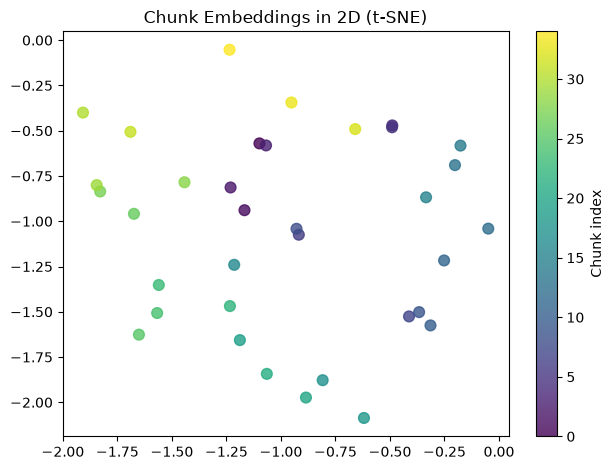

In [ ]:
#Visualizing these embeddings in 2D using Dimensionality Reduction with t-SNE:
#Done using vibe coding with Claude: 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(np.array(embeddings))

plt.scatter(reduced[:, 0], reduced[:, 1], c=range(len(chunks)), cmap="viridis", s=60, alpha=0.8)
plt.colorbar(label="Chunk index")
plt.title("Chunk Embeddings in 2D (t-SNE)")
plt.tight_layout()
plt.show()

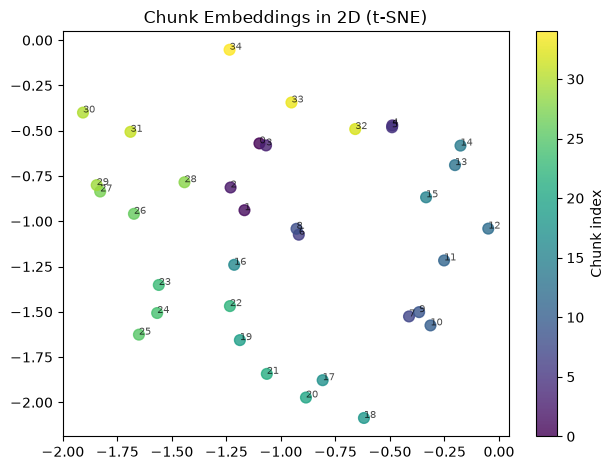

In [13]:
#Asked Claude: add label with chunk number
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(np.array(embeddings))

plt.scatter(reduced[:, 0], reduced[:, 1], c=range(len(chunks)), cmap="viridis", s=60, alpha=0.8)
for i, (x, y) in enumerate(reduced):
    plt.annotate(i, (x, y), fontsize=7, alpha=0.7)
plt.colorbar(label="Chunk index")
plt.title("Chunk Embeddings in 2D (t-SNE)")
plt.tight_layout()
plt.show()

The axes don't matter. They are just fillers

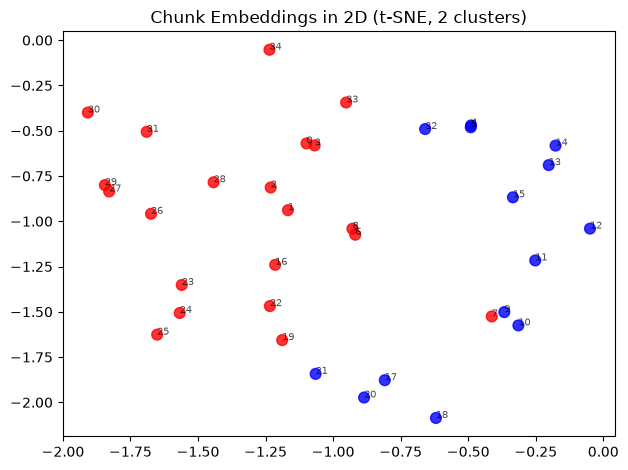

In [14]:
#Asked Claude: identify 2 clusters in the chunks and colour them with 2 colours
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans

matrix = np.array(embeddings)
reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

plt.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap="bwr", s=60, alpha=0.8)
for i, (x, y) in enumerate(reduced):
    plt.annotate(i, (x, y), fontsize=7, alpha=0.7)
plt.title("Chunk Embeddings in 2D (t-SNE, 2 clusters)")
plt.tight_layout()
plt.show()

#Note: KMeans runs on the original high-dimensional embeddings, not the t-SNE reduction — that's intentional, 
# since t-SNE distorts distances and isn't reliable for clustering. The colours just map those cluster assignments 
# onto the 2D plot.

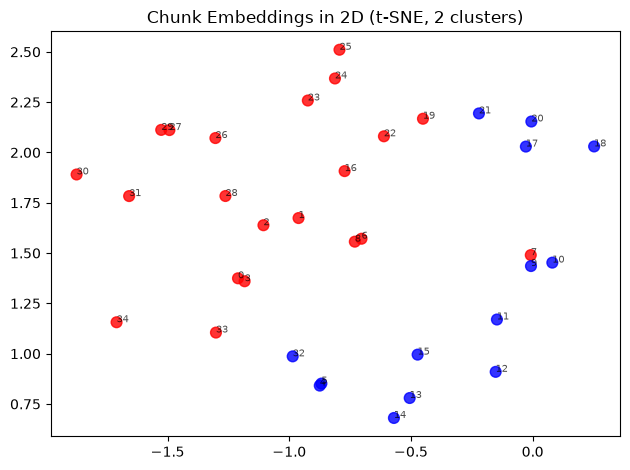

Cluster 0: The common theme of these text chunks centers on building a high-performance workplace culture that prioritizes exceptional talent, candid communication, and accountability over seniority or unconditional loyalty. It emphasizes teamwork modeled on professional sports teams, valuing people above processes, and fostering an environment where feedback, responsibility, and continuous improvement drive collective and individual excellence.

Cluster 1: The common theme of these text chunks is Netflix’s unique culture centered on empowering talented, high-performing individuals through freedom, responsibility, and continuous innovation. It emphasizes boldness, creativity, collaboration, inclusion, and a relentless drive for excellence to deliver exceptional entertainment experiences worldwide.



In [7]:
#Asked Claude: describe each cluster using ChatGPT OpenAI 4.1 mini
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from openai import OpenAI

client = OpenAI()

matrix = np.array(embeddings)
reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

plt.scatter(reduced[:, 0], reduced[:, 1], c=labels, cmap="bwr", s=60, alpha=0.8)
for i, (x, y) in enumerate(reduced):
    plt.annotate(i, (x, y), fontsize=7, alpha=0.7)
plt.title("Chunk Embeddings in 2D (t-SNE, 2 clusters)")
plt.tight_layout()
plt.show()

for cluster_id in range(2):
    cluster_chunks = [chunks[i] for i, label in enumerate(labels) if label == cluster_id]
    combined = "\n\n".join(cluster_chunks)
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[{"role": "user", "content": f"In 2-3 sentences, describe the common theme of these text chunks:\n\n{combined}"}]
    )
    print(f"Cluster {cluster_id}: {response.choices[0].message.content}\n")

*Outcome*:
Cluster 0: The common theme of these text chunks is the emphasis on building and maintaining a high-performance, accountable workplace culture centered around talented individuals who collaborate effectively while upholding values like honesty, respect, and continuous feedback. The organization prioritizes people over processes, fostering autonomy and responsibility, and constantly evolving its culture to drive excellence and long-term success.

Cluster 1: The common theme of these text chunks centers on Netflix’s distinctive company culture that emphasizes high performance, individual autonomy, and continuous improvement. It highlights the importance of boldness, creativity, inclusion, and resilience in fostering an environment where talented people are empowered to do their best work while driving innovation and excellence.

/var/folders/46/_h631_sn18bcs0m630nzymf80000gn/T/ipykernel_79082/4141332447.py:34: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


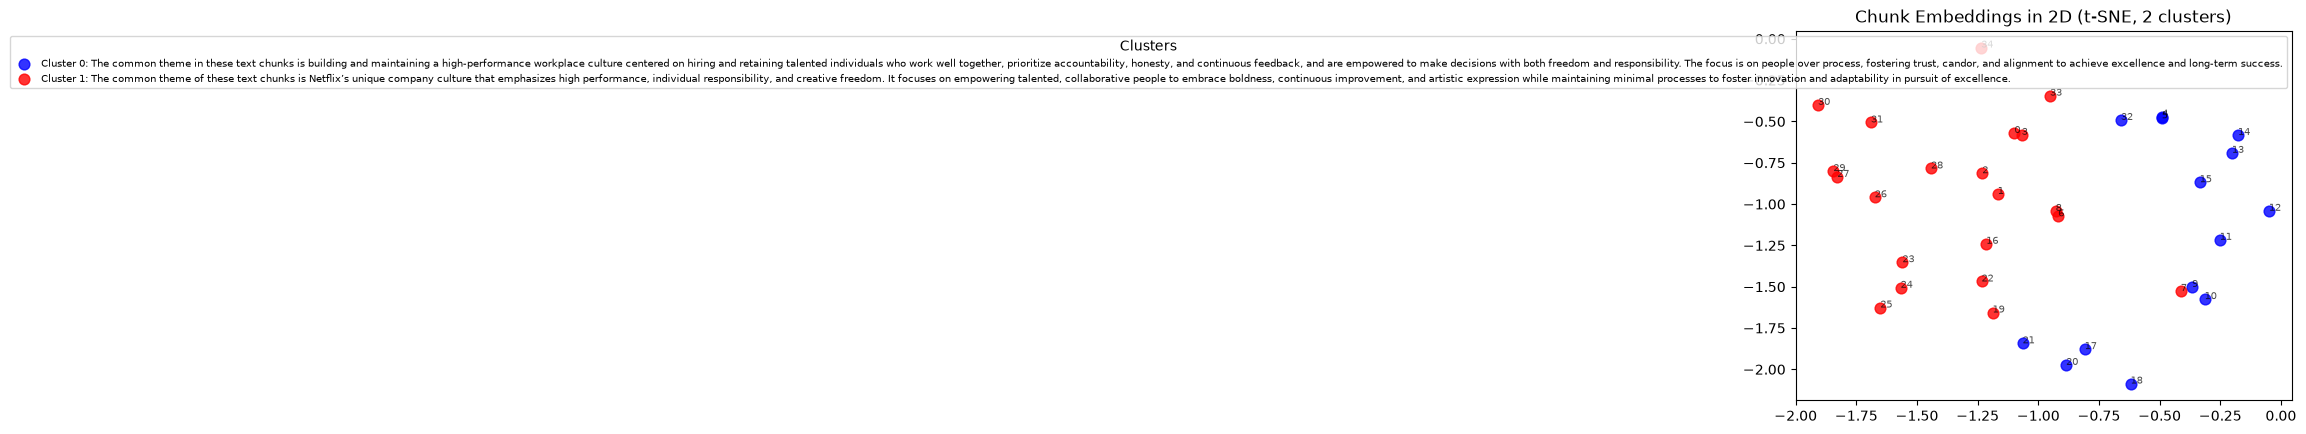

In [18]:
#Asked Claude: Add legend
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from openai import OpenAI

client = OpenAI()

matrix = np.array(embeddings)
reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

descriptions = []
for cluster_id in range(2):
    cluster_chunks = [chunks[i] for i, label in enumerate(labels) if label == cluster_id]
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[{"role": "user", "content": f"In 2-3 sentences, describe the common theme of these text chunks:\n\n{'\n\n'.join(cluster_chunks)}"}]
    )
    descriptions.append(response.choices[0].message.content)

colors = ["blue", "red"]
for cluster_id in range(2):
    mask = labels == cluster_id
    plt.scatter(reduced[mask, 0], reduced[mask, 1], c=colors[cluster_id], s=60, alpha=0.8,
                label=f"Cluster {cluster_id}: {descriptions[cluster_id]}")

for i, (x, y) in enumerate(reduced):
    plt.annotate(i, (x, y), fontsize=7, alpha=0.7)

plt.title("Chunk Embeddings in 2D (t-SNE, 2 clusters)")
plt.legend(loc="best", fontsize=7, title="Clusters", framealpha=0.8)
plt.tight_layout()
plt.show()

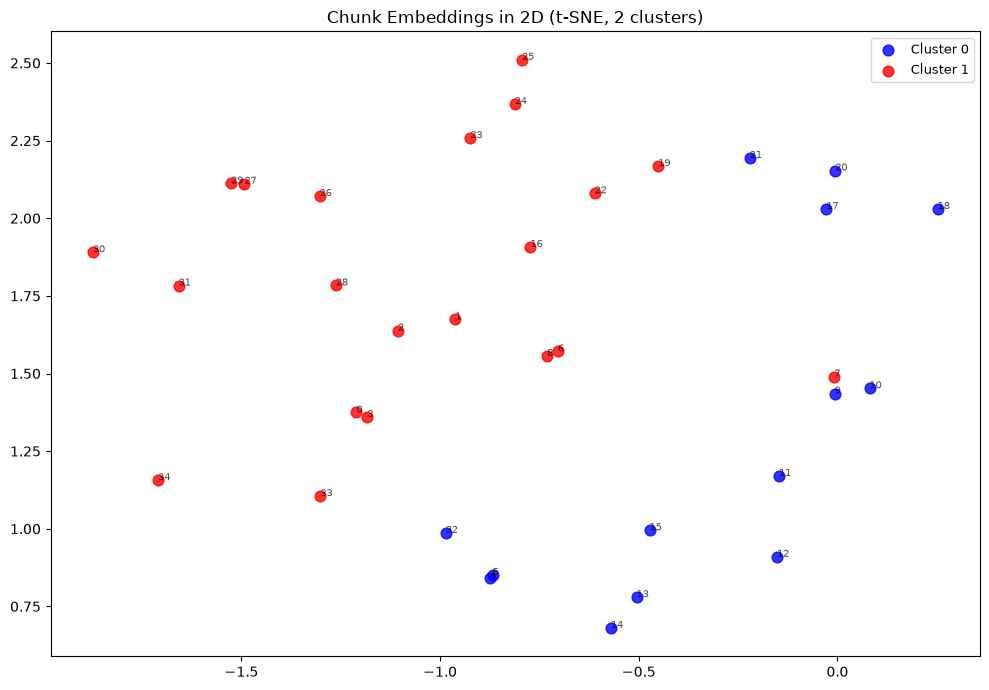

Cluster 0 (blue): The common theme of these text chunks is the emphasis on building a high-performance, accountable workplace culture driven by talented individuals who work well together through trust, honesty, and constructive feedback. The organization values strong professional relationships, merit-based team composition, empowered decision-making, and continual cultural improvement over rigid processes or unconditional loyalty.

Cluster 1 (red): The common theme of these text chunks is Netflix’s unique company culture centered on excellence, empowered autonomy, and continuous improvement. It emphasizes hiring high performers who embrace boldness, creativity, and collaboration while valuing freedom over rigid processes to drive innovation and deliver outstanding entertainment globally.



In [8]:
#Asked Claude: the plot shrank. the legend also shrank. i dont need the full description of the clusters on the plot.
#  just write which colour is which cluster number. put the description after the plot

import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from openai import OpenAI

client = OpenAI()

matrix = np.array(embeddings)
reduced = TSNE(n_components=2, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

descriptions = []
for cluster_id in range(2):
    cluster_chunks = [chunks[i] for i, label in enumerate(labels) if label == cluster_id]
    response = client.chat.completions.create( #doing a call to the AI here
        model="gpt-4.1-mini",
        messages=[{"role": "user", "content": f"In 2-3 sentences, describe the common theme of these text chunks:\n\n{'\n\n'.join(cluster_chunks)}"}]
    )
    descriptions.append(response.choices[0].message.content)

colors = ["blue", "red"]
plt.figure(figsize=(10, 7))
for cluster_id in range(2):
    mask = labels == cluster_id
    plt.scatter(reduced[mask, 0], reduced[mask, 1], c=colors[cluster_id], s=60, alpha=0.8, label=f"Cluster {cluster_id}")

for i, (x, y) in enumerate(reduced):
    plt.annotate(i, (x, y), fontsize=7, alpha=0.7)

plt.title("Chunk Embeddings in 2D (t-SNE, 2 clusters)")
plt.legend(fontsize=9)
plt.tight_layout()
plt.show()

for cluster_id, description in enumerate(descriptions):
    print(f"Cluster {cluster_id} ({colors[cluster_id]}): {description}\n")

*Outcome*: 
Cluster 0 (blue): The common theme of these text chunks centers on cultivating a high-performance workplace culture that prioritizes exceptional talent, accountability, and collaboration. It emphasizes valuing people over processes by fostering trust, candid feedback, responsible decision-making, and continuous improvement to drive collective and individual excellence.

Cluster 1 (red): The common theme of these text chunks is Netflix's distinctive company culture, which emphasizes high performance, individual responsibility, creativity, and continuous improvement. The culture fosters an environment of freedom balanced with accountability, encouraging boldness, collaboration, and resilience to deliver exceptional work while embracing diversity and innovation.

Blue is more focused on collaboration, employees, and their lives.
Red is more focused on company culture and individualism.

For example, **Chunk 15** is blue, so it should focus on collaboration and teamwork.

--- Chunk 15 | 498 chars ---
hild and his dad saying, “That’s a keeper, Reed!”
© 2024 Netflix, Inc. All rights reserved. | Last updated: June 2024 | English Version
In the abstract, the keeper test can sound scary. In reality, we encourage everyone to speak to
their managers about what’s going well and what’s not on a regular basis. This helps avoid
surprises. Managers also evaluate team members on their whole record, rather than focusing
on the mistakes or bets that didn’t pay off. On the Dream Team, you need people who

**This is teamwork-focused**

Taking **Chunk 26** as an example.
Chunk 26 is in Cluster 1, so the red cluster. Thus, it should be more focused on company culture and individualism.

--- Chunk 26 | 415 chars ---
ity and making it harder for businesses to adapt.
You might think that this kind of freedom would lead to chaos. In reality, while we’ve had our
fair share of failures — and a few people have taken advantage of our culture in bad ways —
our emphasis on individual autonomy has created an extremely successful business, with
many opportunities for employees to develop and grow. In entertainment and technology, our

**This is company culture and individual focused**

**Chunk 7 is red, borderline blue, on the 2D Chunk Embeddings:** - so it might be a mix of both

--- Chunk 7 | 463 chars ---
s better together. These are the values we value:
● Selflessness — you are humble when searching for the best ideas; you seek what’s
best for Netflix, not yourself or your team; you take time to help others succeed.
● Judgment — you look beyond short term fixes in favor of long term solutions; you
make wise decisions despite ambiguity; you use data to inform your intuition.
● Candor — you willingly receive and give feedback; you are open about what’s working


Teamwork-focused (mentions team and being selfless). Therefore, it is correctly red. Uses individualism, through the phrase "you", "you", "you"

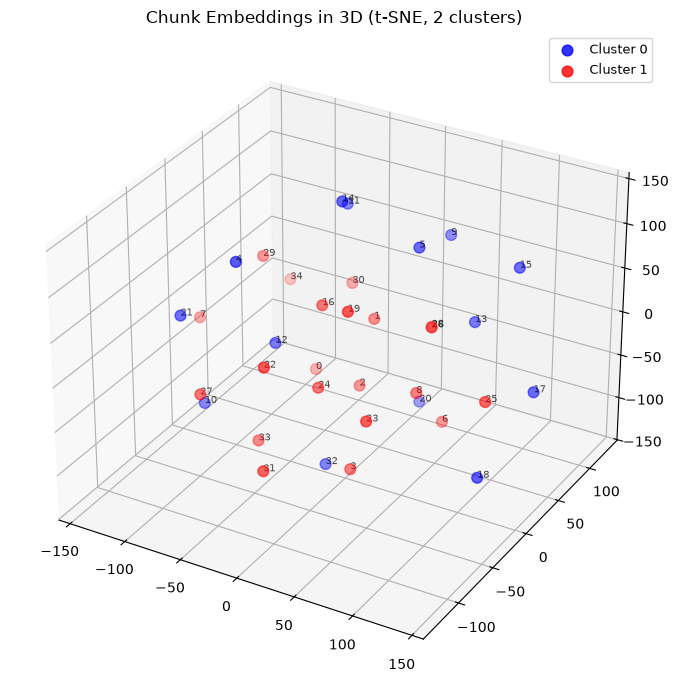

Cluster 0 (blue): The common theme of these text chunks is the emphasis on building a high-performance, accountable workplace culture that prioritizes talent, honesty, and collaboration over tenure or loyalty. The organization values candid feedback, individual responsibility, and empowering teams through context rather than control to continuously improve and innovate.

Cluster 1 (red): The common theme of these text chunks is Netflix’s unique company culture centered on empowering high-performing, responsible individuals through freedom, boldness, and continuous improvement. It emphasizes collaboration, creativity, inclusion, and resilience to drive innovation and deliver exceptional entertainment experiences on a global scale.



In [8]:
#Asked Claude: Great, now in 3D please. And I'd like the plot to be rotatable
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from openai import OpenAI

client = OpenAI()

matrix = np.array(embeddings)
reduced = TSNE(n_components=3, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

descriptions = []
for cluster_id in range(2):
    cluster_chunks = [chunks[i] for i, label in enumerate(labels) if label == cluster_id]
    response = client.chat.completions.create( #Doing the AI call here (API)
        model="gpt-4.1-mini",
        messages=[{"role": "user", "content": f"In 2-3 sentences, describe the common theme of these text chunks:\n\n{'\n\n'.join(cluster_chunks)}"}]
    )
    descriptions.append(response.choices[0].message.content)

colors = ["blue", "red"]
fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")

for cluster_id in range(2):
    mask = labels == cluster_id
    ax.scatter(reduced[mask, 0], reduced[mask, 1], reduced[mask, 2],
               c=colors[cluster_id], s=60, alpha=0.8, label=f"Cluster {cluster_id}")

for i, (x, y, z) in enumerate(reduced):
    ax.text(x, y, z, str(i), fontsize=7, alpha=0.7)

ax.set_title("Chunk Embeddings in 3D (t-SNE, 2 clusters)")
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

for cluster_id, description in enumerate(descriptions):
    print(f"Cluster {cluster_id} ({colors[cluster_id]}): {description}\n")

In [9]:
# Told Claude: it isnt rotatable
import numpy as np
import plotly.graph_objects as go # Matplotlib's 3D isn't truly interactive in Jupyter. Use Plotly instead
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from openai import OpenAI

client = OpenAI()

matrix = np.array(embeddings)
reduced = TSNE(n_components=3, perplexity=min(30, len(embeddings) - 1), random_state=42).fit_transform(matrix)
labels = KMeans(n_clusters=2, random_state=42).fit_predict(matrix)

descriptions = []
for cluster_id in range(2):
    cluster_chunks = [chunks[i] for i, label in enumerate(labels) if label == cluster_id]
    response = client.chat.completions.create(
        model="gpt-4.1-mini",
        messages=[{"role": "user", "content": f"In 2-3 sentences, describe the common theme of these text chunks:\n\n{'\n\n'.join(cluster_chunks)}"}]
    )
    descriptions.append(response.choices[0].message.content)

colors = ["blue", "red"]
fig = go.Figure()

for cluster_id in range(2):
    mask = labels == cluster_id
    indices = np.where(mask)[0]
    fig.add_trace(go.Scatter3d(
        x=reduced[mask, 0], y=reduced[mask, 1], z=reduced[mask, 2],
        mode="markers+text",
        marker=dict(size=5, color=colors[cluster_id], opacity=0.8),
        text=[str(i) for i in indices],
        textfont=dict(size=9),
        name=f"Cluster {cluster_id}"
    ))

fig.update_layout(title="Chunk Embeddings in 3D (t-SNE, 2 clusters)", legend=dict(font=dict(size=12)))
fig.show()

for cluster_id, description in enumerate(descriptions):
    print(f"Cluster {cluster_id} ({colors[cluster_id]}): {description}\n")

Cluster 0 (blue): The common theme of these text chunks is the emphasis on building a high-performing, accountable, and collaborative team by prioritizing talent, trust, and extraordinary candor over tenure or unconditional loyalty. The culture values clear communication, performance-based decisions, and empowering employees with context and responsibility rather than strict control, fostering continuous improvement and excellence.

Cluster 1 (red): The common theme of these text chunks centers on Netflix’s distinctive company culture that prioritizes high performance, individual responsibility, and continuous improvement through freedom and empowerment. It emphasizes boldness, creativity, collaboration, and resilience in pursuing excellence to entertain a global audience while fostering an inclusive environment where employees can do their best work.



*Output*:
Cluster 0 (blue): The common theme of these text chunks centers on fostering a high-performance, accountable workplace culture that values exceptional talent, candid communication, and strong teamwork. It emphasizes prioritizing people over rigid processes, encouraging continuous improvement, and maintaining a collaborative environment where individuals are empowered and held to high standards for the success of the whole team.

Cluster 1 (red): The common theme across these text chunks is Netflix’s unique company culture centered on empowering high-performing, responsible individuals through freedom, boldness, and continuous improvement. It emphasizes fostering creativity, collaboration, inclusion, and resilience while minimizing rigid processes to enable innovation and delivering the best possible work for a diverse global audience.

### Step 5: Initialize ChromaDB and Store Vectors

In [ ]:
#ChromaDB is a vector store. MongaDB is another example vector store. Pinecone is the leading one (most popular)
# https://docs.trychroma.com/reference/python/client
# https://docs.trychroma.com/docs/run-chroma/clients - In-memory client just stays in your code (computer's memory).
# Persistent client exists on your machine (you will still have the data if you restart your IDE). Cloud client is stored on their service (how they make money)

import chromadb
#DB = database
#Initialize ChromaDB client (persistent storage - will show up as a separate file in our folder, so we'll see it on the sidebar)
chroma_client = chromadb.PersistentClient(path = "./chroma_db") #We want to store it in persistent storage (stored on your disk)

#Initialize ChromaDB client (in-memory storage)
#chroma_client = chromadb.Client() #This will create chromadb.Client() in memory storage

collection = chroma_client.get_or_create_collection(name = "netflix_culture") #Creating a collection
# .create works on the first time creating it.
# .get only works when it's already created (doesn't work on the first run)
# therefore, we use .get_or_create

#If we already had the database, we want to make sure we remove all the items from it
if collection.get()["ids"]: #if this is not empty. Checking if it returns something and request the id's
    collection.delete(collection.get()["ids"]) #we want to empty all of these items and then work with our collection
#For testing purpose. NOT in real life.

pprint(collection.get()) #gets us what's inside our collection

{'data': None,
 'documents': [],
 'embeddings': None,
 'ids': [],
 'included': ['metadatas', 'documents'],
 'metadatas': [],
 'uris': None}


{'data': None,
 'documents': [],
 'embeddings': None,
 'ids': [],
 'included': ['metadatas', 'documents'],
 'metadatas': [],
 'uris': None}

Collection is effectively like a table in SQL, but with chunks, vectors, ids, and metadata.
Table is also structured data, whereas a collection is unstructured data. 
(In Pinecone, collection is called index)

In our output: We are interested in 'documents', 'embeddings', 'metadatas', and 'ids' (since every record in your collection has to have an id) for now.

In [12]:
#Prepare data for storage
ids = [f"Chunk_{i}" for i in range(len(chunks))] #we created text for our IDs. Using Chunk # as the ID since we only have 1 document
# Chroma allows you to pick what kind of IDs you want (numeric, text, etc) - Only require every record to have a unique ID
metadatas = [{"source": "netflix_culture_pdf", "chunk_index": i} for i in range(len(chunks))] #chunk_index because we want know what chunk from that document it is
#chunk_index is more important for the metadata (moreso than ids; ids can be random too)

#len(chunk) = 35, so we get ids from 1 to 35, and 35 entries for metadata as well

#Adding data to ChromaDB
collection.add(
    ids = ids, #should have a list of 35 of them since we have 35 chunks
    embeddings = embeddings,
    documents = chunks,
    metadatas = metadatas #helpful to include. will also be a list of 35
)

pprint(collection.get())

{'data': None,
 'documents': ['\n'
               'The Best Work of Our Lives\n'
               'CULTURE MEMO\n'
               'At Netflix, we aspire to entertain the world, thrilling '
               'audiences everywhere. To do that, we’ve\n'
               'developed an unusual company culture focused on excellence, '
               'and creating an environment\n'
               'where talented people can thrive — lifting ourselves, each '
               'other and our audiences higher and\n'
               'higher. This document is about that culture, which is based on '
               'four core principles:\n'
               '● The Dream Team: We aim only to have high performers at '
               'Netflix — people who are\n',
               ' have high performers at Netflix — people who are\n'
               'great at what they do, and even better at working together.\n'
               '● People over Process: You get better outcomes when employees '
               'have the inf

*In the ouput:*
The comma indicates the end of the chunk. 
For example: This is the 1st chunk:

 'documents': ['\n'
               'The Best Work of Our Lives\n'
               'CULTURE MEMO\n'
               'At Netflix, we aspire to entertain the world, thrilling '
               'audiences everywhere. To do that, we’ve\n'
               'developed an unusual company culture focused on excellence, '
               'and creating an environment\n'
               'where talented people can thrive — lifting ourselves, each '
               'other and our audiences higher and\n'
               'higher. This document is about that culture, which is based on '
               'four core principles:\n'
               '● The Dream Team: We aim only to have high performers at '
               'Netflix — people who are\n',

We also get:
 **'embeddings': None,**
 'ids': ['Chunk_0',..., 'Chunk_34'],
 'included': ['metadatas', 'documents'],
 'metadatas': [{'chunk_index': 0, 'source': 'netflix_culture_pdf'}, ..., {'chunk_index': 34, 'source': 'netflix_culture_pdf'}]


'id' is included by default. and then 'included' includes what else was included, so 'metadatas' and 'documents'. 'embeddings' wasn't included because ChromaDB knows this is large and so it doesn't output it to save on resources, costs, etc, unless you tell it explicitly.

In [13]:
pprint(collection.get(include = ["documents", "metadatas", "embeddings"])) #Cannot include ID here because that is always outputted (otherwise you get an error)

{'data': None,
 'documents': ['\n'
               'The Best Work of Our Lives\n'
               'CULTURE MEMO\n'
               'At Netflix, we aspire to entertain the world, thrilling '
               'audiences everywhere. To do that, we’ve\n'
               'developed an unusual company culture focused on excellence, '
               'and creating an environment\n'
               'where talented people can thrive — lifting ourselves, each '
               'other and our audiences higher and\n'
               'higher. This document is about that culture, which is based on '
               'four core principles:\n'
               '● The Dream Team: We aim only to have high performers at '
               'Netflix — people who are\n',
               ' have high performers at Netflix — people who are\n'
               'great at what they do, and even better at working together.\n'
               '● People over Process: You get better outcomes when employees '
               'have the inf

 Now we got embeddings:



 'embeddings': array([[ 0.03387451,  0.01966858, -0.04037476, ...,  0.02305603,
         0.0114212 , -0.05325317],
       [ 0.01805115,  0.01722717, -0.00737   , ..., -0.01236725,
        -0.02839661, -0.04162598],
       [-0.00108624,  0.01222229, -0.02120972, ...,  0.00922394,
        -0.03198242, -0.01811218],
       ...,
       [ 0.03143311,  0.02531433, -0.02200317, ..., -0.01754761,
         0.01433563, -0.02592468],
       [ 0.04748535,  0.01826477, -0.01303101, ..., -0.03009033,
         0.01908875, -0.0199585 ],
       [ 0.02767944,  0.02110291, -0.01260376, ...,  0.0247345 ,
        -0.01820374, -0.03448486]], shape=(35, 1536)),

(still truncated because we have 1500 dimension vectors)

    'included': ['documents', 'metadatas', 'embeddings'],

### Step 6: Test Retrieval

In [14]:
#Generate embedding for a test query
test_query = "days off"

#Embeded the query using the same model we used for the chunks to ensure compatibility
#(need to create vector embedding for this test_query)
#Tip: you will need to convert the query into a list before passing it in

response = client.embeddings.create( #Embedding Model
    model = "text-embedding-3-small", #Need to use same model because we want to be in the same vector space as the actual embeddings we have stored in ChromaDB
# (same dimension space - same coordinates)
    input = [test_query] #square brackets so it turns into a list (applied the tip)
)

query_embedding = response.data[0].embedding #0 since we only have one element in the list that we want to query

#Search ChromaDB
#Tip: use collection.query()
#Tip: you will need to convert the query embedding into a list before passing it in
results = collection.query(
    query_embeddings = [query_embedding], #pass the vectors that we're using for the query. Usually only searching for 1 thing with RAG, so we have a list of 1 element again
    n_results = 3 #how many chunks we want to return. So 3 closest results. Want between 3-5, since with 1, we might not get enough context. With 10, we might get too much context and it might be too long for the model to process. 
    #include = ["documents", "metadatas"] (default) # we don't really need the embeddings.
)


#Verify retrieval works - print which chunks were retrieved and their content
pprint(results)



{'data': None,
 'distances': [[1.4906573295593262, 1.6062387228012085, 1.6187598705291748]],
 'documents': [['a minimum and ensure any process is good (simple,\n'
                'efficient, impactful). Our vacation policy, for example, is '
                'two words: “Take vacation.” And our\n'
                'expenses policy is just five words: “Act in Netflix’s best '
                'interests.” This (almost) no rules rule\n'
                'gives employees the freedom to exercise their judgment. It '
                'also prevents the process creep\n'
                'that typically happens when companies grow and try to dummy '
                'proof their organizations —\n'
                'stifling creativity and making it harder for businesses to '
                'adapt.\n',
                'ions. It takes an unusually responsible person to\n'
                'thrive on this level of freedom — someone who’s '
                'self-motivated, self-aware and\n'
             

In [15]:
# With 2 queries (rare):

#Generate embedding for a test query
test_query = "days off"
test_query2 = "teamwork and collaboration"

#Embeded the query using the same model we used for the chunks to ensure compatibility
#(need to create vector embedding for this test_query)
#Tip: you will need to convert the query into a list before passing it in

response = client.embeddings.create( #Embedding Model
    model = "text-embedding-3-small", #Need to use same model because we want to be in the same vector space as the actual embeddings we have stored in ChromaDB
# (same dimension space - same coordinates)
    input = [test_query, test_query2] #square brackets so it turns into a list (applied the tip)
)

query_embedding = [response.data[0].embedding, response.data[1].embedding] #0 and 1 since we have two elements in the list that we want to query

#Search ChromaDB
#Tip: use collection.query()
#Tip: you will need to convert the query embedding into a list before passing it in
results = collection.query(
    query_embeddings = query_embedding, #pass the vectors that we're using for the query. Usually only searching for 1 thing with RAG, so we have a list of 1 element again
    n_results = 3 #how many chunks we want to return. So 3 closest results. Want between 3-5, since with 1, we might not get enough context. With 10, we might get too much context and it might be too long for the model to process. 
    #include = ["documents", "metadatas"] (default) # we don't really need the embeddings.
)


#Verify retrieval works - print which chunks were retrieved and their content
pprint(results)

{'data': None,
 'distances': [[1.4906573295593262, 1.6062387228012085, 1.6187598705291748],
               [1.0635279417037964, 1.0815891027450562, 1.0865962505340576]],
 'documents': [['a minimum and ensure any process is good (simple,\n'
                'efficient, impactful). Our vacation policy, for example, is '
                'two words: “Take vacation.” And our\n'
                'expenses policy is just five words: “Act in Netflix’s best '
                'interests.” This (almost) no rules rule\n'
                'gives employees the freedom to exercise their judgment. It '
                'also prevents the process creep\n'
                'that typically happens when companies grow and try to dummy '
                'proof their organizations —\n'
                'stifling creativity and making it harder for businesses to '
                'adapt.\n',
                'ions. It takes an unusually responsible person to\n'
                'thrive on this level of freedom — som

 'distances': [[1.4906573295593262, 1.6062387228012085, 1.6187598705291748], <- distances for the 1st query ("days off")
                [1.0635279417037964, 1.0815891027450562, 1.0865962505340576]], <- distances for the 2nd query ("teamwork and collaboration")

We get squared Euclidean distances between the query vector (or embeddings vector) "days off" and "teamwork and collaboration"
1st element in distance is the closest chunk, 2nd one is 2nd closest chunk, 3rd is 3rd closest chunk (for each of the respective queries) in the 1500 dimension space.


 'ids': [['Chunk_24', 'Chunk_18', 'Chunk_17'], <- closest chunks for the 1st query
         ['Chunk_15', 'Chunk_20', 'Chunk_6']], <- closest chunks for the 2nd query

In [20]:
#Generate embedding for a test query
test_query = "days off"

#Embeded the query using the same model we used for the chunks to ensure compatibility
#(need to create vector embedding for this test_query)
#Tip: you will need to convert the query into a list before passing it in

response = client.embeddings.create( #Embedding Model
    model = "text-embedding-3-small", #Need to use same model because we want to be in the same vector space as the actual embeddings we have stored in ChromaDB
# (same dimension space - same coordinates)
    input = [test_query] #square brackets so it turns into a list (applied the tip)
)

query_embedding = response.data[0].embedding #0 since we only have one element in the list that we want to query

#Search ChromaDB
#Tip: use collection.query()
#Tip: you will need to convert the query embedding into a list before passing it in
results = collection.query(
    query_embeddings = [query_embedding], #pass the vectors that we're using for the query. Usually only searching for 1 thing with RAG, so we have a list of 1 element again
    n_results = 3 #how many chunks we want to return. So 3 closest results. Want between 3-5, since with 1, we might not get enough context. With 10, we might get too much context and it might be too long for the model to process. 
    #include = ["documents", "metadatas"] (default) # we don't really need the embeddings.
)


#Verify retrieval works - print which chunks were retrieved and their content
#pprint(results)

print(f"Query: {test_query}\n")
print("Retrieved Chunks:") #zip takes 2 lists and combines them into a single list of tuples. Each tuple contains one element from each of the input lists. In this case, it combines the retrieved chunks and their corresponding metadata.
for chunk, metadata in zip(results["documents"][0], results["metadatas"][0]):
    print(f"Chunk {metadata['chunk_index']}: \n{chunk}\n")

Query: days off

Retrieved Chunks:
Chunk 24: 
a minimum and ensure any process is good (simple,
efficient, impactful). Our vacation policy, for example, is two words: “Take vacation.” And our
expenses policy is just five words: “Act in Netflix’s best interests.” This (almost) no rules rule
gives employees the freedom to exercise their judgment. It also prevents the process creep
that typically happens when companies grow and try to dummy proof their organizations —
stifling creativity and making it harder for businesses to adapt.


Chunk 18: 
ions. It takes an unusually responsible person to
thrive on this level of freedom — someone who’s self-motivated, self-aware and
self-disciplined, who doesn’t wait to be told what to do and picks up the trash like they would
at home. That said, context not control should not be confused with hands-off management.
Managers need to be involved in the work being done around them, and actively coach their
teams. They may also have to step in when some

So just Chunk 24 talks about days off.
We got Chunk 18 and then 17 as well because we asked for 3 chunks.

In [21]:
pprint(results)

{'data': None,
 'distances': [[1.4907279014587402, 1.6062121391296387, 1.6187660694122314]],
 'documents': [['a minimum and ensure any process is good (simple,\n'
                'efficient, impactful). Our vacation policy, for example, is '
                'two words: “Take vacation.” And our\n'
                'expenses policy is just five words: “Act in Netflix’s best '
                'interests.” This (almost) no rules rule\n'
                'gives employees the freedom to exercise their judgment. It '
                'also prevents the process creep\n'
                'that typically happens when companies grow and try to dummy '
                'proof their organizations —\n'
                'stifling creativity and making it harder for businesses to '
                'adapt.\n',
                'ions. It takes an unusually responsible person to\n'
                'thrive on this level of freedom — someone who’s '
                'self-motivated, self-aware and\n'
             

 'distances': [[1.4907279014587402, 1.6062121391296387, 1.6187660694122314]]

 We see that the difference between Chunk 24 and 18 is greater than the distance between Chunk 18 and 17. (because Chunk 17 and 18 are not related to the query)

This is a demonstration of **fuzzy matching in RAG** as it is able to match days off with vacation. (as no days off was explicitly written in the document).
Thus, RAG beats dynamic context.

### Step 7: Function to Process the Conversation Turn (with RAG)

In [36]:
system_message = f"You are a helpful Netflix HR assistant that answers employee questions based on the provided Netflix Culture document: {document}. \
    Always use all the available information to provide the best answer possible."

In [38]:
def response_ai(message, history):

    #RAG
    #Embeded the query using the same model we used for the chunks to ensure compatibility
    response = client.embeddings.create( #Embedding Model
        model = "text-embedding-3-small", #Need to use same model because we want to be in the same vector space as the actual embeddings we have stored in ChromaDB (same dimension space - same coordinates)
        input = [message] #square brackets so it turns into a list (applied the tip)
    )
    query_embedding = response.data[0].embedding #0 since we only have one element in the list that we want to query

    #Search ChromaDB
    results = collection.query(
        query_embeddings = [query_embedding], #pass the vectors that we're using for the query. Usually only searching for 1 thing with RAG, so we have a list of 1 element again
        n_results = 3 #how many chunks we want to return. So 3 closest results. Want between 3-5, since with 1, we might not get enough context. With 10, we might get too much context and it might be too long for the model to process. 
    #   include = ["documents", "metadatas"] (default) # we don't really need the embeddings.
    )

    #Stitch retrieved chunks together into a single string to provide context for the AI to respond to the user query. We separate each chunk with "---" for clarity.
    context = "\n---\n".join(results["documents"][0]) #join all the results into a single string, separated by "---" for clarity. This will be used as context for the AI to answer the question.
    
    #Update the system message to include the context from the retrieved chunks. This will help the AI provide a more accurate and informed response to the user's query (for this conversation turn)
    system_message_enhanced = system_message + "\n\nContext:\n" + context

    #As usual:
    messages = [{"role": "system", "content": system_message_enhanced}] + history + [{"role": "user", "content": message}]
    #print("System Message used for the this message:\n", system_message_enhanced) #Debugging line to see the final system message
    response = client.chat.completions.create(
    messages = messages,
    model = "gpt-4.1-mini"
    )

    reply = response.choices[0].message.content
    return reply

gr.ChatInterface(fn = response_ai).launch(inbrowser = True)

* Running on local URL:  http://127.0.0.1:7865
* To create a public link, set `share=True` in `launch()`.


#### **RAG Improvement Methods (a non-exhaustive list)**


1. **Increase n_results** - Retrieve more chunks

results = collection.query(query_embeddings=[embedding], n_results=10)



2. **Adjust chunk size** - Larger chunks for more context

chunks = chunk_text(document, chunk_size=1000, overlap=100)


3. **Increase overlap** - More shared text between chunks

chunks = chunk_text(document, chunk_size=500, overlap=150)


4. **Reranking** - Retrieve many, rerank to pick best

#reranker from sentence-transformers or Cohere
results = collection.query(query_embeddings=[embedding], n_results=20)
reranked = reranker.rank(query, results['documents'][0])[:5]


5. **Query expansion** - Multiple phrasings of same question

queries = ["Netflix values", "company principles", "employee expectations"]
results = collection.query(query_embeddings=embed_all(queries), n_results=5)


6. **Parent-child retrieval** - Match on small chunks, return parent section

metadata = {"chunk_id": "chunk_7", "parent_section": "THE DREAM TEAM"}
#When chunk_7 matches, retrieve all chunks with same parent_section


7. **Sliding window context** - Grab neighboring chunks

matched_idx = 7
context_indices = [matched_idx - 1, matched_idx, matched_idx + 1, matched_idx + 2]
context_chunks = [chunks[i] for i in context_indices if 0 <= i < len(chunks)]


8. **Metadata filtering** - Filter by source, language, date before search

results = collection.query(
    query_embeddings=[embedding],
    where={"language": "es"}
)


9. **Semantic chunking** - Split by meaning, not character count

#SemanticChunker from langchain_experimental
chunks = semantic_splitter.split(document)


10. **Hybrid search** - Vector + keyword search combined

#bm25_search from rank_bm25 library
vector_results = collection.query(query_embeddings=[embedding])
keyword_results = bm25_search(query, documents)
final_results = merge_and_dedupe(vector_results, keyword_results)


11. **Proposition-based indexing** - Store LLM-extracted facts alongside chunks

propositions = llm.extract("List key facts from this chunk", chunk)
#Store both chunk and propositions, link them together


12. **Agentic RAG** - LLM decides if more retrieval needed

answer = llm.generate(context=chunks, query=query)
if llm.check("Is this answer complete?", answer) == "No":
    new_results = collection.query(query_embeddings=embed(refined_query))